---

# LOGIKA UI 2026 | XGBoost Credit Risk Baseline

*Point-in-time multi-table feature engineering and reproducible five-fold KS validation.*

---

## Team / participant information

Team: **[Fill in registered team name]**  
Participant number: **[Fill in official number]**  
Authors: **[Fill in member names]**

---

## Table of Contents

1. [Introduction](#1)
2. [Initialization](#2)
3. [Data Audit](#3)
4. [Point-in-Time Features](#4)
5. [Validation Design](#5)
6. [Model Training](#6)
7. [Evaluation](#7)
8. [Submission](#8)
9. [Reproduction Notes](#9)

---

# 1. Introduction <a name="1"></a>

---

## Overview

*DSC LOGIKA UI 2026 asks teams to rank Indonesian consumer loans by their probability of reaching 90 or more days past due within twelve months of origination.*

## Aim

*Establish a transparent XGBoost CPU baseline without external datasets, with the exact same engineered features, validation folds and scoring code used in the other two notebooks.*

## Metric

*The official metric is the absolute two-sample Kolmogorov-Smirnov statistic between model risk scores for targets 1 and 0. Higher scores are better; no classification threshold is required.*

$$KS = \sup_s |F_{1}(s) - F_{0}(s)|$$

## Dataset

*The competition provides 70,000 labeled and 30,000 unlabeled applications, customer profiles, prior applications, repayments, account behavior, bureau reports and e-commerce records.*

**Feature sources:** loan and affordability data; customer profiles; past lending; historical repayment; account monthly summaries; bureau; e-commerce.

**Target:** `target` = 1 for serious repayment difficulty (90+ DPD).

## Approach

*Original DuckDB point-in-time SQL creates 63 features; constant `term_months` is excluded, leaving 62 candidate model features. Five shuffled stratified folds are evaluated without early-stopping leakage, followed by an independent retrospective time-stress analysis and full-data final fit.*

---

# 2. Initialization <a name="2"></a>

---

## Environment Setup

The competition dataset should be attached through **Add Input**. All three notebooks are CPU-first; no GPU or internet-hosted data is required.

In [1]:
!nvidia-smi || true

Sun Oct 11 12:34:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

The following cell installs the SQL engine and the model package inside the active Kaggle kernel. Turn on Internet in Notebook Settings if these packages are not already installed.

In [2]:
%pip -q install "duckdb==1.4.1" "xgboost==3.1.3"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 78.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 MB 17.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


## Import Libraries

All libraries are imported once. Their versions are recorded with model outputs.

In [3]:
import hashlib
import json
import os
import platform
import random
import time
from dataclasses import dataclass
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.stats import ks_2samp
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split
import xgboost as xgb
import joblib
from scipy import sparse
from sklearn.preprocessing import OneHotEncoder


## Seed Everything

A single fixed seed controls fold assignment, inner splits and training.

In [4]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)

seed_everything(42)

## Settings

Every input location, output location and model setting is centralized here. The competition path supplied by the user is tried first; standard Kaggle mount paths are supported automatically.

In [5]:
@dataclass
class Settings:
    MODEL_NAME: str = 'xgboost'
    SEED: int = 42
    FOLDS: int = 5
    INNER_VALID_FRACTION: float = 0.20
    MAX_ROUNDS: int = 2000
    EARLY_STOPPING_ROUNDS: int = 100
    THREADS: int = 4
    INPUT_ROOT: Path = Path("/kaggle/input")
    PREFERRED_DATA_DIR: Path = Path("/kaggle/input/competitions/data-science-competition-logika-ui-2026")
    OUTPUT_ROOT: Path = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs/notebooks")
    CATEGORICALS: tuple = ("loan_purpose", "region", "employment_type", "housing_status")
    METADATA: tuple = ("application_id", "customer_id", "split", "target", "decision_datetime")
    EXPECTED_FEATURES: int = 62
    EXPECTED_TRAIN: int = 70000
    EXPECTED_TEST: int = 30000

CFG = Settings()
CFG.OUT = CFG.OUTPUT_ROOT / CFG.MODEL_NAME
CFG.OUT.mkdir(parents=True, exist_ok=True)
print("Model:", 'XGBoost', "Output directory:", CFG.OUT)

Model: XGBoost Output directory: /kaggle/working/xgboost


## Load Dataset

The selected directory must contain all committee CSVs. `DATA_DICTIONARY.md` is read for documentation only, never as an additional feature source.

In [6]:
INPUT_FILES = (
    "train_applications.csv", "test_applications.csv", "customer_profiles.csv",
    "previous_applications.csv", "repayment_history.csv", "account_behavior.csv",
    "bureau_observations.csv", "ecommerce_transactions.csv", "sample_submission.csv",
)

def resolve_data_directory():
    if CFG.PREFERRED_DATA_DIR.is_dir() and (CFG.PREFERRED_DATA_DIR / "train_applications.csv").is_file():
        candidates = [CFG.PREFERRED_DATA_DIR]
    elif CFG.INPUT_ROOT.is_dir():
        candidates = sorted(set(p.parent for p in CFG.INPUT_ROOT.rglob("train_applications.csv")))
    else:
        candidates = sorted(set(p.parent for p in Path.cwd().rglob("train_applications.csv")))
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Expected exactly one committee data directory; found {len(candidates)}: {candidates}. "
            "Attach the competition data using Add Input on Kaggle."
        )
    folder = candidates[0]
    missing = [name for name in INPUT_FILES if not (folder / name).is_file()]
    if missing:
        raise FileNotFoundError(f"Missing required committee CSVs in {folder}: {missing}")
    return folder

CFG.DATA_DIR = resolve_data_directory()
sample = pd.read_csv(CFG.DATA_DIR / "sample_submission.csv")
assert sample.columns.tolist() == ["application_id", "default_probability"], sample.columns.tolist()
assert sample.application_id.is_unique and not sample.application_id.isna().any()
print("Competition files:", CFG.DATA_DIR)
print("Sample submission:", sample.shape)
if (CFG.DATA_DIR / "DATA_DICTIONARY.md").exists():
    print("Data dictionary located:", CFG.DATA_DIR / "DATA_DICTIONARY.md")

Competition files: /kaggle/input/competitions/data-science-competition-logika-ui-2026
Sample submission: (30000, 2)
Data dictionary located: /kaggle/input/competitions/data-science-competition-logika-ui-2026/DATA_DICTIONARY.md


---

# 3. Data Audit <a name="3"></a>

---

The model uses only the eight input data tables, and only features observable at each selected application decision date. The train/test application IDs and labels are checked before generating features.

In [7]:
train_raw = pd.read_csv(CFG.DATA_DIR / "train_applications.csv")
test_raw = pd.read_csv(CFG.DATA_DIR / "test_applications.csv")
assert train_raw.application_id.is_unique and test_raw.application_id.is_unique
assert train_raw.customer_id.is_unique and test_raw.customer_id.is_unique
assert not set(train_raw.application_id) & set(test_raw.application_id)
assert not set(train_raw.customer_id) & set(test_raw.customer_id)
assert len(train_raw) == CFG.EXPECTED_TRAIN and len(test_raw) == CFG.EXPECTED_TEST
assert set(train_raw.target.dropna().unique()) == {0, 1}
assert set(sample.application_id) == set(test_raw.application_id)
assert len(sample) == CFG.EXPECTED_TEST
print("Train:", train_raw.shape, "Test:", test_raw.shape)
print("Positive label rate:", round(train_raw.target.mean(), 6))
print("Train dates:", train_raw.decision_datetime.min(), "to", train_raw.decision_datetime.max())

Train: (70000, 10) Test: (30000, 9)
Positive label rate: 0.135814
Train dates: 2025-01-01 08:00:00 to 2025-12-28 20:59:00


#### Insights

> IDs, split integrity and class balance are checked against the expected competition inventory before any model is fit.

---

# 4. Point-in-Time Features <a name="4"></a>

---

The following DuckDB transformations reproduce the existing audited 63-column feature pipeline directly from the competition CSVs. Previous applications, installment repayments, monthly account data, bureau snapshots and individual e-commerce orders are all constrained to the selected decision time.

In [8]:
TABLE_NAMES = (
    "train_applications", "test_applications", "customer_profiles",
    "previous_applications", "repayment_history", "account_behavior",
    "bureau_observations", "ecommerce_transactions",
)
feature_t0 = time.perf_counter()
con = duckdb.connect(database=":memory:")
con.execute(f"SET threads = {CFG.THREADS}")
for table in TABLE_NAMES:
    csv_path = str(CFG.DATA_DIR / f"{table}.csv").replace("'", "''")
    con.execute(f"CREATE VIEW {table} AS SELECT * FROM read_csv_auto('{csv_path}')")
con.execute("""
    CREATE TEMP TABLE applications AS
    SELECT *, 'train' AS split FROM train_applications
    UNION ALL BY NAME
    SELECT *, 'test' AS split FROM test_applications
""")
print("DuckDB views loaded:", len(TABLE_NAMES))

DuckDB views loaded: 8


In [9]:
con.execute('CREATE TEMP TABLE base AS\n    SELECT a.application_id, a.customer_id, a.split, a.target,\n           a.decision_datetime, EXTRACT(MONTH FROM a.decision_datetime) AS decision_month,\n           a.loan_amount, a.term_months, a.annual_interest_rate,\n           a.proposed_monthly_installment, a.loan_purpose,\n           p.age, p.region, p.employment_type, p.employment_tenure_months,\n           p.declared_monthly_income, p.dependents, p.housing_status,\n           a.proposed_monthly_installment / NULLIF(p.declared_monthly_income, 0)\n               AS installment_income_ratio,\n           a.loan_amount / NULLIF(12 * p.declared_monthly_income, 0)\n               AS loan_annual_income_ratio\n    FROM applications a LEFT JOIN customer_profiles p USING (customer_id)')
print("Built SQL table: base")

Built SQL table: base


In [10]:
con.execute('CREATE TEMP TABLE previous_eligible AS\n    SELECT a.application_id AS selected_application_id, h.*,\n           a.decision_datetime AS selected_decision_datetime\n    FROM applications a JOIN previous_applications h USING (customer_id)\n    WHERE h.decision_datetime < a.decision_datetime')
print("Built SQL table: previous_eligible")

Built SQL table: previous_eligible


In [11]:
con.execute("CREATE TEMP TABLE previous_features AS\n    SELECT selected_application_id AS application_id,\n           COUNT(*) AS previous_count,\n           COUNT(*) FILTER (WHERE decision = 'approved') AS previous_approved_count,\n           COUNT(*) FILTER (WHERE decision = 'rejected') AS previous_rejected_count,\n           COUNT(*) FILTER (WHERE decision = 'cancelled') AS previous_cancelled_count,\n           AVG(requested_amount) AS previous_requested_mean,\n           AVG(approved_amount) AS previous_approved_amount_mean,\n           date_diff('day', MAX(decision_datetime), MAX(selected_decision_datetime))\n               AS previous_recency_days\n    FROM previous_eligible GROUP BY 1")
print("Built SQL table: previous_features")

Built SQL table: previous_features


In [12]:
con.execute("CREATE TEMP TABLE repayment_features AS\n    SELECT p.selected_application_id AS application_id,\n           COUNT(DISTINCT r.loan_id) AS historical_loan_count,\n           COUNT(*) AS due_installment_count,\n           AVG(r.days_past_due) AS repayment_mean_dpd,\n           MAX(r.max_days_past_due) AS repayment_max_historical_dpd,\n           AVG(CAST(r.days_past_due > 0 AS DOUBLE)) AS repayment_late_share,\n           AVG(CAST(r.days_past_due >= 30 AS DOUBLE)) AS repayment_30dpd_share,\n           SUM(GREATEST(r.amount_due - r.amount_paid, 0)) AS repayment_due_shortfall,\n           SUM(r.amount_paid) / NULLIF(SUM(r.amount_due), 0) AS repayment_paid_due_ratio\n    FROM previous_eligible p JOIN repayment_history r\n      ON p.loan_id = r.loan_id AND p.customer_id = r.customer_id\n    WHERE p.decision = 'approved'\n      AND r.due_date < p.selected_decision_datetime\n      AND (r.last_payment_datetime IS NULL\n           OR r.last_payment_datetime < p.selected_decision_datetime)\n    GROUP BY 1")
print("Built SQL table: repayment_features")

Built SQL table: repayment_features


In [13]:
con.execute('CREATE TEMP TABLE account_features AS\n    SELECT a.application_id, COUNT(*) AS account_complete_months,\n           AVG(h.average_balance) AS account_average_balance,\n           AVG(h.minimum_balance) AS account_minimum_balance_mean,\n           AVG(h.low_balance_days) AS account_low_balance_days_mean,\n           STDDEV_POP(h.inflows - h.outflows) AS account_net_flow_volatility,\n           AVG(h.inflows - h.outflows) AS account_net_flow_mean,\n           AVG(h.income_like_credits) AS account_income_like_mean,\n           AVG(h.average_balance) FILTER (\n               WHERE h.month >= CAST(a.decision_datetime - INTERVAL 3 MONTH AS DATE)\n           ) AS account_3m_average_balance,\n           AVG(h.low_balance_days) FILTER (\n               WHERE h.month >= CAST(a.decision_datetime - INTERVAL 3 MONTH AS DATE)\n           ) AS account_3m_low_balance_days_mean,\n           AVG(h.inflows - h.outflows) FILTER (\n               WHERE h.month >= CAST(a.decision_datetime - INTERVAL 6 MONTH AS DATE)\n           ) AS account_6m_net_flow_mean\n    FROM applications a JOIN account_behavior h USING (customer_id)\n    WHERE CAST(h.month AS TIMESTAMP) + INTERVAL 1 MONTH <= a.decision_datetime\n    GROUP BY 1')
print("Built SQL table: account_features")

Built SQL table: account_features


In [14]:
con.execute('CREATE TEMP TABLE bureau_eligible AS\n    SELECT b.*, a.application_id AS selected_application_id, a.decision_datetime,\n           ROW_NUMBER() OVER (\n               PARTITION BY a.application_id, b.bureau_provider\n               ORDER BY b.available_datetime DESC, b.report_datetime DESC,\n                        b.bureau_observation_id DESC\n           ) AS provider_rank\n    FROM bureau_observations b JOIN applications a USING (customer_id)\n    WHERE b.available_datetime <= a.decision_datetime\n      AND b.report_datetime <= a.decision_datetime')
print("Built SQL table: bureau_eligible")

Built SQL table: bureau_eligible


In [15]:
con.execute("CREATE TEMP TABLE bureau_features AS\n    SELECT selected_application_id AS application_id,\n           COUNT(*) AS bureau_report_count,\n           COUNT(*) FILTER (WHERE application_id <> selected_application_id)\n               AS bureau_prior_report_count,\n           COUNT(*) FILTER (WHERE provider_rank = 1) AS bureau_provider_count,\n           AVG(score) FILTER (WHERE provider_rank = 1) AS bureau_score_mean,\n           MIN(score) FILTER (WHERE provider_rank = 1) AS bureau_score_min,\n           MAX(delinquent_accounts_last_12m) FILTER (WHERE provider_rank = 1)\n               AS bureau_delinquent_accounts_max,\n           MAX(inquiries_last_6m) FILTER (WHERE provider_rank = 1)\n               AS bureau_inquiries_6m_max,\n           AVG(utilization) FILTER (WHERE provider_rank = 1) AS bureau_utilization_mean,\n           MAX(outstanding_balance) FILTER (WHERE provider_rank = 1)\n               AS bureau_outstanding_max,\n           MAX(revolving_outstanding_balance) FILTER (WHERE provider_rank = 1)\n               AS bureau_revolving_balance_max,\n           MIN(date_diff('day', available_datetime, decision_datetime))\n               AS bureau_freshest_age_days,\n           COUNT(*) FILTER (WHERE provider_rank = 1 AND score IS NULL)\n               AS bureau_unscored_provider_count\n    FROM bureau_eligible GROUP BY 1")
print("Built SQL table: bureau_features")

Built SQL table: bureau_features


In [16]:
con.execute('CREATE TEMP TABLE valid_items AS\n    SELECT a.application_id, a.decision_datetime, h.order_id,\n           h.transaction_datetime, h.product_category, h.item_total,\n           h.order_total, h.payment_method, h.order_status\n    FROM applications a JOIN ecommerce_transactions h USING (customer_id)\n    WHERE h.transaction_datetime < a.decision_datetime')
print("Built SQL table: valid_items")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Built SQL table: valid_items


In [17]:
con.execute('CREATE TEMP TABLE order_events AS\n    SELECT application_id, decision_datetime, order_id, transaction_datetime,\n           payment_method, order_status, MAX(order_total) AS order_total\n    FROM valid_items\n    GROUP BY 1, 2, 3, 4, 5, 6')
print("Built SQL table: order_events")

Built SQL table: order_events


In [18]:
con.execute("CREATE TEMP TABLE ecommerce_orders AS\n    SELECT application_id, COUNT(*) AS ecommerce_order_count,\n           COUNT(*) FILTER (WHERE order_status = 'completed') AS ecommerce_completed_count,\n           COUNT(*) FILTER (WHERE order_status = 'cancelled') AS ecommerce_cancelled_count,\n           SUM(order_total) FILTER (WHERE order_status = 'completed') AS ecommerce_spend,\n           SUM(order_total) FILTER (\n               WHERE order_status = 'completed'\n                 AND transaction_datetime >= decision_datetime - INTERVAL 90 DAY\n           ) AS ecommerce_90d_spend,\n           COUNT(*) FILTER (\n               WHERE order_status = 'completed'\n                 AND transaction_datetime >= decision_datetime - INTERVAL 90 DAY\n           ) AS ecommerce_90d_orders,\n           AVG(CAST(payment_method = 'COD' AS DOUBLE)) AS ecommerce_cod_share,\n           AVG(CAST(payment_method = 'credit_card' AS DOUBLE)) AS ecommerce_credit_card_share,\n           MAX(transaction_datetime) AS last_ecommerce_datetime,\n           MAX(decision_datetime) AS decision_datetime\n    FROM order_events GROUP BY 1")
print("Built SQL table: ecommerce_orders")

Built SQL table: ecommerce_orders


In [19]:
con.execute("CREATE TEMP TABLE ecommerce_items AS\n    SELECT application_id,\n           COUNT(DISTINCT product_category) FILTER (\n               WHERE order_status = 'completed') AS ecommerce_unique_categories,\n           SUM(item_total) FILTER (\n               WHERE order_status = 'completed' AND product_category = 'electronics'\n           ) AS ecommerce_electronics_spend\n    FROM valid_items GROUP BY 1")
print("Built SQL table: ecommerce_items")

Built SQL table: ecommerce_items


The final one-row-per-application join combines the independently aggregated feature families.

In [20]:
con.execute("CREATE TEMP TABLE features AS\n    SELECT b.*,\n           COALESCE(p.previous_count, 0) AS previous_count,\n           COALESCE(p.previous_approved_count, 0) AS previous_approved_count,\n           COALESCE(p.previous_rejected_count, 0) AS previous_rejected_count,\n           COALESCE(p.previous_cancelled_count, 0) AS previous_cancelled_count,\n           p.previous_requested_mean, p.previous_approved_amount_mean,\n           p.previous_recency_days,\n           COALESCE(r.historical_loan_count, 0) AS historical_loan_count,\n           COALESCE(r.due_installment_count, 0) AS due_installment_count,\n           r.repayment_mean_dpd, r.repayment_max_historical_dpd,\n           r.repayment_late_share, r.repayment_30dpd_share,\n           r.repayment_due_shortfall, r.repayment_paid_due_ratio,\n           COALESCE(ac.account_complete_months, 0) AS account_complete_months,\n           ac.account_average_balance, ac.account_minimum_balance_mean,\n           ac.account_low_balance_days_mean, ac.account_net_flow_volatility,\n           ac.account_net_flow_mean, ac.account_income_like_mean,\n           ac.account_3m_average_balance, ac.account_3m_low_balance_days_mean,\n           ac.account_6m_net_flow_mean,\n           COALESCE(bu.bureau_report_count, 0) AS bureau_report_count,\n           COALESCE(bu.bureau_prior_report_count, 0) AS bureau_prior_report_count,\n           COALESCE(bu.bureau_provider_count, 0) AS bureau_provider_count,\n           bu.bureau_score_mean, bu.bureau_score_min,\n           bu.bureau_delinquent_accounts_max, bu.bureau_inquiries_6m_max,\n           bu.bureau_utilization_mean, bu.bureau_outstanding_max,\n           bu.bureau_revolving_balance_max, bu.bureau_freshest_age_days,\n           bu.bureau_unscored_provider_count,\n           COALESCE(eo.ecommerce_order_count, 0) AS ecommerce_order_count,\n           COALESCE(eo.ecommerce_completed_count, 0) AS ecommerce_completed_count,\n           COALESCE(eo.ecommerce_cancelled_count, 0) AS ecommerce_cancelled_count,\n           eo.ecommerce_spend, eo.ecommerce_90d_spend,\n           COALESCE(eo.ecommerce_90d_orders, 0) AS ecommerce_90d_orders,\n           eo.ecommerce_cod_share, eo.ecommerce_credit_card_share,\n           date_diff('day', eo.last_ecommerce_datetime, b.decision_datetime)\n               AS ecommerce_recency_days,\n           ei.ecommerce_unique_categories, ei.ecommerce_electronics_spend\n    FROM base b\n    LEFT JOIN previous_features p USING (application_id)\n    LEFT JOIN repayment_features r USING (application_id)\n    LEFT JOIN account_features ac USING (application_id)\n    LEFT JOIN bureau_features bu USING (application_id)\n    LEFT JOIN ecommerce_orders eo USING (application_id)\n    LEFT JOIN ecommerce_items ei USING (application_id)")
print("Built SQL table: features")

Built SQL table: features


The feature table is materialized once. Identifiers and the selected raw timestamp are retained only for validation, not passed to the classifier.

In [21]:
features_all = con.execute("SELECT * FROM features").df()
con.close()
features_all["decision_datetime"] = pd.to_datetime(features_all["decision_datetime"])
train_df = features_all.loc[features_all.split == "train"].sort_values("application_id").reset_index(drop=True)
test_df = features_all.loc[features_all.split == "test"].sort_values("application_id").reset_index(drop=True)
feature_cols = [c for c in features_all.columns if c not in CFG.METADATA and c != "term_months"]
assert len(feature_cols) == CFG.EXPECTED_FEATURES, (len(feature_cols), feature_cols)
assert len(train_df) == CFG.EXPECTED_TRAIN and len(test_df) == CFG.EXPECTED_TEST
assert train_df.application_id.is_unique and test_df.application_id.is_unique
assert set(train_df.application_id) == set(train_raw.application_id)
assert set(test_df.application_id) == set(test_raw.application_id)
assert set(sample.application_id) == set(test_df.application_id)
assert train_df.customer_id.is_unique and test_df.customer_id.is_unique
assert not set(train_df.customer_id) & set(test_df.customer_id)
assert train_df.target.notna().all() and set(train_df.target.unique()) == {0, 1}
assert test_df.target.isna().all()
assert train_df.term_months.nunique(dropna=False) == 1
assert set(CFG.CATEGORICALS).issubset(feature_cols)
for name in feature_cols:
    if name not in CFG.CATEGORICALS:
        train_df[name] = pd.to_numeric(train_df[name], errors="raise").astype("float32")
        test_df[name] = pd.to_numeric(test_df[name], errors="raise").astype("float32")
        assert np.isfinite(train_df[name].dropna().to_numpy()).all(), name
        assert np.isfinite(test_df[name].dropna().to_numpy()).all(), name
print("Feature rows:", len(train_df), len(test_df), "model features:", len(feature_cols))
feature_elapsed = time.perf_counter() - feature_t0
print("Feature SQL elapsed seconds:", round(feature_elapsed, 1))
print("Categorical feature families:", CFG.CATEGORICALS)
print("Column inventory:", feature_cols)

Feature rows: 70000 30000 model features: 62
Feature SQL elapsed seconds: 18.1
Categorical feature families: ('loan_purpose', 'region', 'employment_type', 'housing_status')
Column inventory: ['decision_month', 'loan_amount', 'annual_interest_rate', 'proposed_monthly_installment', 'loan_purpose', 'age', 'region', 'employment_type', 'employment_tenure_months', 'declared_monthly_income', 'dependents', 'housing_status', 'installment_income_ratio', 'loan_annual_income_ratio', 'previous_count', 'previous_approved_count', 'previous_rejected_count', 'previous_cancelled_count', 'previous_requested_mean', 'previous_approved_amount_mean', 'previous_recency_days', 'historical_loan_count', 'due_installment_count', 'repayment_mean_dpd', 'repayment_max_historical_dpd', 'repayment_late_share', 'repayment_30dpd_share', 'repayment_due_shortfall', 'repayment_paid_due_ratio', 'account_complete_months', 'account_average_balance', 'account_minimum_balance_mean', 'account_low_balance_days_mean', 'account_net

#### Insights

> Exactly 62 non-constant model features are used. Numeric missingness remains missing, and historical event counts without records are set to zero by the audited SQL. No raw ID, label or selected timestamp enters the model.

---

# 5. Validation Design <a name="5"></a>

---

One deterministic five-fold stratified split is generated after sorting IDs. Each outer fold is strictly held out from inner early stopping and any fitted categorical encoding. The fold manifest and SHA-256 hash enable direct comparison across notebooks.

In [22]:
y = train_df.target.astype("int8").to_numpy()
fold_index = np.full(len(train_df), -1, dtype=np.int8)
outer_cv = StratifiedKFold(n_splits=CFG.FOLDS, shuffle=True, random_state=CFG.SEED)
outer_splits = list(outer_cv.split(train_df, y))
for fold, (idx_train, idx_valid) in enumerate(outer_splits):
    fold_index[idx_valid] = fold
    assert not set(train_df.iloc[idx_train].customer_id) & set(train_df.iloc[idx_valid].customer_id)
assert (fold_index >= 0).all()
folds = train_df[["application_id"]].copy()
folds["fold"] = fold_index
fold_manifest = folds.to_csv(index=False, lineterminator="\n")
fold_digest = hashlib.sha256(fold_manifest.encode("utf-8")).hexdigest()
folds.to_csv(CFG.OUT / "folds.csv", index=False)
print("Five-fold SHA-256 digest:", fold_digest)
print(folds.groupby("fold").size().to_string())
print(train_df.groupby(fold_index).target.agg(["size", "mean"]).to_string())

def score_metrics(y_true, probabilities):
    positives = np.asarray(probabilities)[np.asarray(y_true) == 1]
    negatives = np.asarray(probabilities)[np.asarray(y_true) == 0]
    if not len(positives) or not len(negatives):
        return {"ks": 0.0, "roc_auc": float("nan"), "average_precision": float("nan")}
    return {
        "ks": float(ks_2samp(positives, negatives).statistic),
        "roc_auc": float(roc_auc_score(y_true, probabilities)),
        "average_precision": float(average_precision_score(y_true, probabilities)),
    }

print("Official KS function and fold contract ready.")

Five-fold SHA-256 digest: a233781ed128e2fde13e5ae58ee78b049b602872558fefc07c044c892dafc4f4
fold
0    14000
1    14000
2    14000
3    14000
4    14000
    size      mean
0  14000  0.135786
1  14000  0.135786
2  14000  0.135786
3  14000  0.135857
4  14000  0.135857
Official KS function and fold contract ready.


#### Insights

> The digest is expected to be identical across LightGBM, XGBoost and CatBoost. Pooled out-of-fold KS is calculated on predictions from models that never trained on their respective validation rows.

---

# 6. Model Training <a name="6"></a>

---

The first baseline uses a fixed tree configuration, no class weighting and binary log loss as the early-stopping surrogate. Category conversion, one-hot vocabularies or CatBoost pools are learned only from the training slice passed to each fit.

In [23]:
def model_train_predict(fit_part, pred_part, rounds, eval_part=None):
    numeric = [c for c in feature_cols if c not in CFG.CATEGORICALS]
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32)

    def extract_cats(part):
        return part[list(CFG.CATEGORICALS)].astype("string").fillna("__MISSING__")

    encoder.fit(extract_cats(fit_part))

    def transform(part):
        num = sparse.csr_matrix(part[numeric].to_numpy(dtype=np.float32))
        cat = encoder.transform(extract_cats(part))
        return sparse.hstack((num, cat), format="csr", dtype=np.float32)

    X_fit = transform(fit_part)
    X_pred = transform(pred_part)
    names = numeric + encoder.get_feature_names_out(list(CFG.CATEGORICALS)).tolist()
    model_kwargs = dict(
        objective="binary:logistic", tree_method="hist", eval_metric="logloss",
        n_estimators=int(rounds), learning_rate=0.03, max_depth=5,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=3.0,
        random_state=CFG.SEED, n_jobs=CFG.THREADS,
    )
    if eval_part is not None:
        model_kwargs["early_stopping_rounds"] = CFG.EARLY_STOPPING_ROUNDS
    model = xgb.XGBClassifier(**model_kwargs)
    fit_kwargs = {}
    if eval_part is not None:
        fit_kwargs["eval_set"] = [(transform(eval_part), eval_part.target.astype(int))]
        fit_kwargs["verbose"] = False
    model.fit(X_fit, fit_part.target.astype(int), **fit_kwargs)
    best_rounds = int(model.best_iteration + 1) if eval_part is not None else int(rounds)
    probabilities = model.predict_proba(X_pred)[:, 1]
    importance = np.asarray(model.feature_importances_)
    return probabilities, best_rounds, model, importance, names, encoder


Each outer fold performs an independent stratified inner validation to choose a boosting round, then retrains on the entire outer training partition. The untouched outer validation row receives exactly one prediction.

In [24]:
train_t0 = time.perf_counter()
oof = np.full(len(train_df), np.nan, dtype=np.float64)
selected_rounds = []
fold_results = []
fold_importances = []

for fold, (outer_train_idx, outer_valid_idx) in enumerate(outer_splits):
    inner_train_idx, inner_valid_idx = train_test_split(
        outer_train_idx,
        test_size=CFG.INNER_VALID_FRACTION,
        stratify=y[outer_train_idx],
        random_state=CFG.SEED + fold,
    )
    _, best_round, _, _, _, _ = model_train_predict(
        train_df.iloc[inner_train_idx], train_df.iloc[inner_valid_idx],
        rounds=CFG.MAX_ROUNDS, eval_part=train_df.iloc[inner_valid_idx],
    )
    assert 1 <= best_round <= CFG.MAX_ROUNDS
    scores, _, fitted, importance, names, _ = model_train_predict(
        train_df.iloc[outer_train_idx], train_df.iloc[outer_valid_idx],
        rounds=best_round,
    )
    assert np.isfinite(scores).all()
    oof[outer_valid_idx] = scores
    metrics = score_metrics(y[outer_valid_idx], scores)
    metrics.update({"fold": int(fold), "n_validation": int(len(outer_valid_idx)), "best_round": int(best_round)})
    fold_results.append(metrics)
    fold_importances.append(pd.Series(importance, index=names).rename(f"fold_{fold}"))
    selected_rounds.append(int(best_round))
    print(f"Fold {fold}: KS={metrics['ks']:.5f}, AUC={metrics['roc_auc']:.5f}, AP={metrics['average_precision']:.5f}, rounds={best_round}")

assert np.isfinite(oof).all() and np.std(oof) > 0
cv_elapsed = time.perf_counter() - train_t0
fold_metrics = pd.DataFrame(fold_results)
pooled_metrics = score_metrics(y, oof)
print("\nPer-fold mean KS:", fold_metrics.ks.mean(), "+/-", fold_metrics.ks.std(ddof=1))
print("Pooled OOF KS:", pooled_metrics["ks"])
print("Total CV seconds:", round(cv_elapsed, 1))
fold_metrics.to_csv(CFG.OUT / "fold_metrics.csv", index=False)
oof_df = train_df[["application_id", "target"]].copy()
oof_df["fold"] = fold_index
oof_df["score"] = oof
oof_df.to_csv(CFG.OUT / f"oof_{CFG.MODEL_NAME}.csv", index=False)
feature_importance = pd.concat(fold_importances, axis=1).fillna(0).mean(axis=1).sort_values(ascending=False)
feature_importance.rename("mean_importance").to_csv(CFG.OUT / "feature_importance.csv", header=True)
print("Most important features:", feature_importance.head(12).to_dict())

Fold 0: KS=0.47428, AUC=0.81626, AP=0.44426, rounds=440
Fold 1: KS=0.49894, AUC=0.82580, AP=0.45604, rounds=424
Fold 2: KS=0.47476, AUC=0.81179, AP=0.44129, rounds=468
Fold 3: KS=0.47031, AUC=0.81111, AP=0.43850, rounds=320
Fold 4: KS=0.49358, AUC=0.82525, AP=0.46094, rounds=363

Per-fold mean KS: 0.4823745499492915 +/- 0.012932454017692052
Pooled OOF KS: 0.47902838510466905
Total CV seconds: 67.6
Most important features: {'repayment_max_historical_dpd': 0.09933517128229141, 'ecommerce_recency_days': 0.06261061131954193, 'ecommerce_90d_spend': 0.05218189209699631, 'repayment_mean_dpd': 0.047803256660699844, 'bureau_score_mean': 0.046240225434303284, 'repayment_late_share': 0.03948654979467392, 'repayment_paid_due_ratio': 0.03389095515012741, 'repayment_30dpd_share': 0.02860340103507042, 'bureau_score_min': 0.026903185993433, 'due_installment_count': 0.022082755342125893, 'annual_interest_rate': 0.020729651674628258, 'ecommerce_90d_orders': 0.015955712646245956}


The time-stress check fits a model using January through September decisions and scores October through December decisions. It is **retrospective** because the first nine months of loan outcomes would not all be mature by October 2025.

In [25]:
date_year = train_df.decision_datetime.dt.year
assert date_year.eq(2025).all(), "Temporal stress window was designed for 2025 decisions"
months = train_df.decision_datetime.dt.month
time_train = np.flatnonzero(months.le(9).to_numpy())
time_valid = np.flatnonzero(months.ge(10).to_numpy())
assert len(time_train) and len(time_valid) and not set(time_train) & set(time_valid)
temporal_t0 = time.perf_counter()
time_inner_train, time_inner_valid = train_test_split(
    time_train, stratify=y[time_train],
    test_size=CFG.INNER_VALID_FRACTION, random_state=CFG.SEED,
)
_, temporal_rounds, _, _, _, _ = model_train_predict(
    train_df.iloc[time_inner_train], train_df.iloc[time_inner_valid],
    rounds=CFG.MAX_ROUNDS, eval_part=train_df.iloc[time_inner_valid],
)
temporal_prob, _, _, _, _, _ = model_train_predict(
    train_df.iloc[time_train], train_df.iloc[time_valid], rounds=temporal_rounds,
)
temporal_metrics = score_metrics(y[time_valid], temporal_prob)
temporal_metrics.update({"n_train": int(len(time_train)), "n_validation": int(len(time_valid)), "best_round": temporal_rounds,
                         "elapsed_seconds": round(time.perf_counter() - temporal_t0, 2)})
print("Retrospective Jan-Sep -> Oct-Dec:", temporal_metrics)
pd.DataFrame({"application_id": train_df.iloc[time_valid].application_id.values,
              "target": y[time_valid], "score": temporal_prob}).to_csv(
    CFG.OUT / "temporal_stress_scores.csv", index=False)

Retrospective Jan-Sep -> Oct-Dec: {'ks': 0.47782738508318084, 'roc_auc': 0.8159465703786111, 'average_precision': 0.45145111505451646, 'n_train': 52413, 'n_validation': 17587, 'best_round': 437, 'elapsed_seconds': 13.59}


#### Insights

> The outer-fold KS values quantify held-out score separation. The time stress score tests distribution sensitivity and must not be interpreted as a prospective deployment simulation.

---

# 7. Evaluation <a name="7"></a>

---

Diagnostics complement official KS with ROC-AUC, average precision, positive/negative score CDFs, risk-decile rates and feature attribution. All plots refer to the pooled **out-of-fold** predictions rather than in-sample fits.

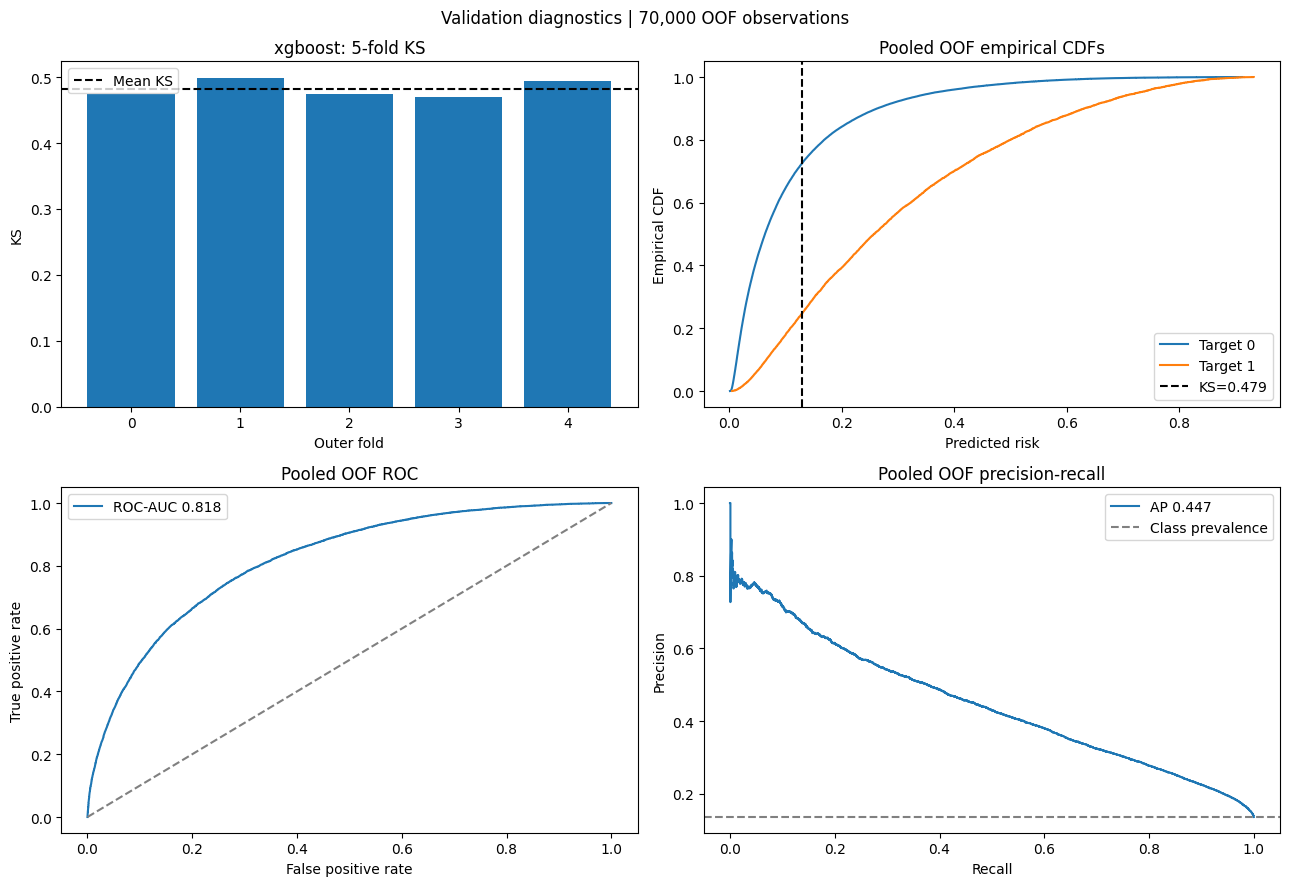

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].bar(fold_metrics.fold.astype(str), fold_metrics.ks)
axes[0, 0].axhline(fold_metrics.ks.mean(), color="black", linestyle="--", label="Mean KS")
axes[0, 0].set(title=f"{CFG.MODEL_NAME}: 5-fold KS", xlabel="Outer fold", ylabel="KS")
axes[0, 0].legend()

positive = np.sort(oof[y == 1])
negative = np.sort(oof[y == 0])
axes[0, 1].step(negative, np.arange(1, len(negative) + 1) / len(negative), where="post", label="Target 0")
axes[0, 1].step(positive, np.arange(1, len(positive) + 1) / len(positive), where="post", label="Target 1")
ks_at = ks_2samp(positive, negative).statistic_location
axes[0, 1].axvline(ks_at, linestyle="--", color="black", label=f"KS={pooled_metrics['ks']:.3f}")
axes[0, 1].set(title="Pooled OOF empirical CDFs", xlabel="Predicted risk", ylabel="Empirical CDF")
axes[0, 1].legend()

fpr, tpr, _ = roc_curve(y, oof)
axes[1, 0].plot(fpr, tpr, label=f"ROC-AUC {pooled_metrics['roc_auc']:.3f}")
axes[1, 0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1, 0].set(title="Pooled OOF ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[1, 0].legend()

precision, recall, _ = precision_recall_curve(y, oof)
axes[1, 1].plot(recall, precision, label=f"AP {pooled_metrics['average_precision']:.3f}")
axes[1, 1].axhline(y.mean(), linestyle="--", color="gray", label="Class prevalence")
axes[1, 1].set(title="Pooled OOF precision-recall", xlabel="Recall", ylabel="Precision")
axes[1, 1].legend()

fig.suptitle(f"Validation diagnostics | {len(train_df):,} OOF observations")
fig.tight_layout()
fig.savefig(CFG.OUT / "validation_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

Risk deciles summarize observed default rates from low-scored to high-scored applications. Decile assignment is descriptive; the competition metric does not use a classification threshold.

 risk_decile    n  observed_default_rate  mean_score  min_score  max_score
           1 7000               0.007143    0.009763   0.001615   0.014802
           2 7000               0.017286    0.019764   0.014803   0.025005
           3 7000               0.027429    0.031126   0.025005   0.037839
           4 7000               0.047571    0.045886   0.037839   0.054775
           5 7000               0.070571    0.065216   0.054776   0.076691
           6 7000               0.091571    0.090580   0.076692   0.106098
           7 7000               0.133714    0.125942   0.106105   0.148479
           8 7000                   0.18    0.179230   0.148496   0.216565
           9 7000               0.279714    0.271349   0.216566   0.343166
          10 7000               0.503143    0.509784   0.343222   0.932613


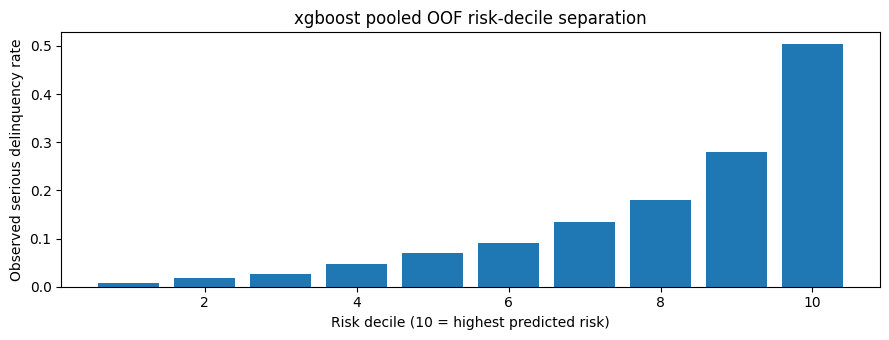

In [27]:
deciles = oof_df.copy()
deciles["risk_decile"] = pd.qcut(deciles.score.rank(method="first"), q=10, labels=False) + 1
decile_table = deciles.groupby("risk_decile", observed=True).agg(
    n=("target", "size"), observed_default_rate=("target", "mean"),
    mean_score=("score", "mean"), min_score=("score", "min"), max_score=("score", "max"),
).reset_index()
print(decile_table.to_string(index=False))
decile_table.to_csv(CFG.OUT / "risk_deciles.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(decile_table.risk_decile, decile_table.observed_default_rate)
ax.set(xlabel="Risk decile (10 = highest predicted risk)", ylabel="Observed serious delinquency rate",
       title=f"{CFG.MODEL_NAME} pooled OOF risk-decile separation")
fig.tight_layout()
fig.savefig(CFG.OUT / "risk_deciles.png", dpi=150, bbox_inches="tight")
plt.show()

To examine feature-family relevance, importance is averaged across the five outer-fold models; one-hot columns are first aggregated to their original categorical source. Importance is an association with the model, not evidence of causality or point-in-time validity.

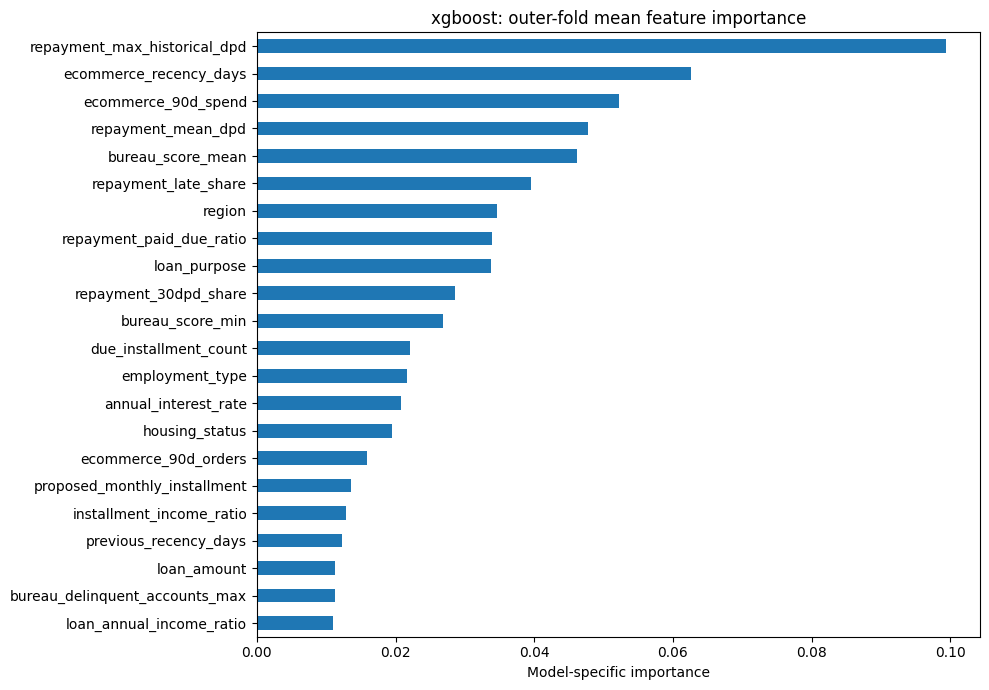

                feature history     n  positives       ks  roc_auc  average_precision
         previous_count    none 21000       2461 0.443084 0.792141           0.343303
         previous_count present 49000       7046 0.494318 0.826525           0.478248
  due_installment_count    none 23688       2878 0.444884 0.792891           0.355146
  due_installment_count present 46312       6629 0.497558 0.828503           0.481374
account_complete_months    none 21000       2461 0.443084 0.792141           0.343303
account_complete_months present 49000       7046 0.494318 0.826525           0.478248


In [28]:
importance_for_plot = feature_importance.copy()
if CFG.MODEL_NAME == "xgboost":
    group_importance = {}
    for name, value in feature_importance.items():
        src = next((c for c in CFG.CATEGORICALS if name.startswith(c + "_")), name)
        group_importance[src] = group_importance.get(src, 0.0) + float(value)
    importance_for_plot = pd.Series(group_importance).sort_values(ascending=False)
importance_for_plot.rename("mean_importance").to_csv(CFG.OUT / "feature_importance_grouped.csv", header=True)
fig, ax = plt.subplots(figsize=(10, 7))
importance_for_plot.head(22).sort_values().plot.barh(ax=ax)
ax.set(title=f"{CFG.MODEL_NAME}: outer-fold mean feature importance", xlabel="Model-specific importance")
fig.tight_layout()
fig.savefig(CFG.OUT / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

subgroup_results = []
for flag in ("previous_count", "due_installment_count", "account_complete_months"):
    for group, mask in (("none", train_df[flag].fillna(0).eq(0)), ("present", train_df[flag].fillna(0).gt(0))):
        sub_y = y[mask.to_numpy()]
        sub_score = oof[mask.to_numpy()]
        m = score_metrics(sub_y, sub_score)
        subgroup_results.append({"feature": flag, "history": group, "n": int(len(sub_y)),
                                 "positives": int(sub_y.sum()), **m})
subgroup_metrics = pd.DataFrame(subgroup_results)
print(subgroup_metrics.to_string(index=False))
subgroup_metrics.to_csv(CFG.OUT / "history_subgroups.csv", index=False)

#### Insights

> Strong bureau, affordability, repayment or spending importance would be consistent with the prior EDA, but neither stability nor absence of leakage follows from feature importance alone. Compare temporal and no-history subgroups before choosing a final candidate.

---

# 8. Submission <a name="8"></a>

---

A single final model is refit on all labeled applications. Its boosting rounds are fixed to the median selected inner-validation count from the outer folds; no test labels or extra data enter training.

In [29]:
final_rounds = max(1, int(np.median(selected_rounds)))
full_t0 = time.perf_counter()
test_scores, _, final_model, final_importance, final_names, final_encoder = model_train_predict(
    train_df, test_df, rounds=final_rounds,
)
full_elapsed = time.perf_counter() - full_t0
assert len(test_scores) == len(test_df) == len(sample)
assert np.isfinite(test_scores).all()
assert np.all((test_scores >= 0) & (test_scores <= 1))
assert np.ptp(test_scores) > 1e-8, "Predictions unexpectedly constant"

pred_df = pd.DataFrame({"application_id": test_df.application_id, "default_probability": test_scores})
submission_df = sample[["application_id"]].merge(pred_df, on="application_id", how="left", validate="one_to_one", sort=False)
assert submission_df.columns.tolist() == ["application_id", "default_probability"]
assert submission_df.application_id.tolist() == sample.application_id.tolist()
assert submission_df.application_id.is_unique
assert len(submission_df) == CFG.EXPECTED_TEST
assert submission_df.default_probability.notna().all()
assert np.isfinite(submission_df.default_probability.to_numpy()).all()
assert submission_df.default_probability.between(0, 1).all()
assert np.ptp(submission_df.default_probability.to_numpy()) > 1e-8
submission_path = CFG.OUTPUT_ROOT / f"submission_{CFG.MODEL_NAME}.csv"
submission_df.to_csv(submission_path, index=False)
submission_df.to_csv(CFG.OUT / f"submission_{CFG.MODEL_NAME}.csv", index=False)
print("Final fit + inference seconds:", round(full_elapsed, 2))
print("Final rounds:", final_rounds)
print("Created:", submission_path)
print(submission_df.head().to_string(index=False))

Final fit + inference seconds: 5.11
Final rounds: 424
Created: /kaggle/working/submission_xgboost.csv
    application_id  default_probability
A_a4f0104b642c9af0             0.007989
A_08d66c9e92ab0b7d             0.137171
A_9a520f63bdee8684             0.504213
A_7ccd9c4aa0f036b1             0.007618
A_559cc08a9c7fa719             0.040032


The fitted model is serialized for later comparison and inference. XGBoost also saves its full-data one-hot encoder; the other two frameworks carry their categorical representations in the trained model.

In [30]:
model_file = CFG.OUT / "xgboost_final_model.json"
final_model.save_model(str(model_file))
encoder_file = CFG.OUT / "xgboost_full_encoder.joblib"
joblib.dump(final_encoder, encoder_file)
print("Saved model:", model_file, "and encoder:", encoder_file)

Saved model: /kaggle/working/xgboost/xgboost_final_model.json and encoder: /kaggle/working/xgboost/xgboost_full_encoder.joblib


The metrics JSON captures actual fold scores, the time stress result, input-feature names, execution times, and dependency versions. No fabricated local model scores are embedded in this notebook.

In [31]:
versions = {
    "python": platform.python_version(), "duckdb": duckdb.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "model_package": {"lightgbm": "lightgbm", "xgboost": "xgboost", "catboost": "catboost"}[CFG.MODEL_NAME],
    "model_version": {"lightgbm": lgb.__version__ if CFG.MODEL_NAME == "lightgbm" else None,
                      "xgboost": xgb.__version__ if CFG.MODEL_NAME == "xgboost" else None,
                      "catboost": cb.__version__ if CFG.MODEL_NAME == "catboost" else None}[CFG.MODEL_NAME],
}
run_report = {
    "model": CFG.MODEL_NAME, "seed": CFG.SEED, "fold_sha256": fold_digest,
    "features": feature_cols, "feature_count": len(feature_cols), "categoricals": list(CFG.CATEGORICALS),
    "n_train": len(train_df), "n_test": len(test_df), "positives": int(y.sum()),
    "folds": fold_results,
    "mean_fold_ks": float(fold_metrics.ks.mean()),
    "std_fold_ks": float(fold_metrics.ks.std(ddof=1)),
    "pooled_oof": pooled_metrics,
    "retrospective_temporal_stress": temporal_metrics,
    "final_rounds": final_rounds, "cv_seconds": round(cv_elapsed, 2),
    "feature_engineering_seconds": round(feature_elapsed, 2),
    "final_fit_and_test_inference_seconds": round(full_elapsed, 2),
    "early_stopping_metric": "binary_logloss" if CFG.MODEL_NAME == "lightgbm" else "logloss",
    "versions": versions,
}
metrics_file = CFG.OUT / f"metrics_{CFG.MODEL_NAME}.json"
metrics_file.write_text(json.dumps(run_report, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: run_report[k] for k in ("model", "fold_sha256", "mean_fold_ks", "pooled_oof", "retrospective_temporal_stress", "final_rounds", "versions")}, indent=2))
print("Metrics written:", metrics_file)

{
  "model": "xgboost",
  "fold_sha256": "a233781ed128e2fde13e5ae58ee78b049b602872558fefc07c044c892dafc4f4",
  "mean_fold_ks": 0.4823745499492915,
  "pooled_oof": {
    "ks": 0.47902838510466905,
    "roc_auc": 0.8180198738373448,
    "average_precision": 0.4474315832638532
  },
  "retrospective_temporal_stress": {
    "ks": 0.47782738508318084,
    "roc_auc": 0.8159465703786111,
    "average_precision": 0.45145111505451646,
    "n_train": 52413,
    "n_validation": 17587,
    "best_round": 437,
    "elapsed_seconds": 13.59
  },
  "final_rounds": 424,
  "versions": {
    "python": "3.13.15",
    "duckdb": "1.4.1",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scipy": "1.16.3",
    "scikit_learn": "1.6.1",
    "model_package": "xgboost",
    "model_version": "3.1.3"
  }
}
Metrics written: /kaggle/working/xgboost/metrics_xgboost.json


#### Insights

> The Kaggle-ready submission has exactly 30,000 unique IDs, two required columns, and finite nonconstant probabilities in the allowed range. Full-data model refitting does not change the previously computed out-of-fold diagnostics.

---

# 9. Reproduction Notes <a name="9"></a>

---

This notebook runs independently using only committee CSVs from `/kaggle/input/competitions/data-science-competition-logika-ui-2026` or another unique attached Kaggle input directory. It uses **CPU**, four threads and seed 42; the first cell installs DuckDB and the selected model dependency.

All outputs are saved in `/kaggle/working/xgboost/`, with the ready-to-upload CSV also at `/kaggle/working/submission_xgboost.csv`. Use **Run All**, then **Save Version**, then download the submission from the notebook **Output**. Actual scores and installed version strings are recorded in the run-specific metrics JSON.

**Validation limitation:** The Jan-Sep / Oct-Dec split is retrospective, not a prospective operational backtest, because a twelve-month default label is not fully mature at the October 2025 cutoff.

**Competition delivery:** After selecting a single final model, rename the designated notebook file to `ParticipantNumber_TeamName_Notebook.ipynb` using the actual registered participant number and team name.